# Credit Card Default Risk
## Exploratory data analysis

**Data:** Default of Credit Card Clients (30,000 customers, April to September 2005)  
**Target:** `Default_Next_Month` (1 = the customer defaulted on the following month's payment)

Run the cells in order. In cell 2, set `DATA_PATH` to the location of the dataset file in Colab. Each section is one cell followed by a short note with its main finding.

| Part | Sections |
|---|---|
| Data preparation | 1 Setup, 2 Load, 3 Audit and labels, 4 Outliers, 5 Features |
| Exploratory analysis | 6 to 19 |
| Conclusions | 20 Recommendations |

### 1. Setup

*Libraries, plotting style and helper functions used throughout the notebook.*

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

SEED = 42

TEAL, CORAL, NAVY, GOLD, GREY = "#2a9d8f", "#e76f51", "#264653", "#e9c46a", "#8d99ae"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.grid.axis": "y"})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=170, bbox_inches="tight")
    plt.show()


def pct(v, d=1):
    return f"{v * 100:.{d}f}%"


def rate_bar(ax, groups, target, title, color, order=None, rot=0):
    """Bar chart of default rate per group, annotated with group size."""
    t = pd.DataFrame({"g": groups, "y": target}).groupby("g", observed=True)["y"].agg(["mean", "count"])
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    ax.bar(t.index.astype(str), t["mean"] * 100, color=color)
    for i, (m, n) in enumerate(zip(t["mean"], t["count"])):
        ax.text(i, m * 100, f"{m*100:.1f}%\nn={n:,}", ha="center", va="bottom", fontsize=8.5,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.6, alpha=0.85))
    ax.axhline(target.mean() * 100, color="black", ls="--", lw=1, label=f"Portfolio {target.mean()*100:.1f}%")
    ax.set_title(title)
    ax.set_ylabel("Default rate (%)")
    ax.set_ylim(0, t["mean"].max() * 130)
    ax.tick_params(axis="x", rotation=rot)
    ax.legend(loc="upper right", fontsize=8)
    return t

### 2. Load and standardise the data

*Locate the file, read it, and give every column a descriptive name (the source calls September 'PAY_0' and has no 'PAY_1').*

In [2]:
# Paste the path of your file from the Colab Files panel (right-click the file > Copy path)
DATA_PATH = "/content/default of credit card clients.xls"

raw = pd.read_excel(DATA_PATH, header=1)

source_cols = {"Sep": ("PAY_0", "BILL_AMT1", "PAY_AMT1"), "Aug": ("PAY_2", "BILL_AMT2", "PAY_AMT2"),
               "Jul": ("PAY_3", "BILL_AMT3", "PAY_AMT3"), "Jun": ("PAY_4", "BILL_AMT4", "PAY_AMT4"),
               "May": ("PAY_5", "BILL_AMT5", "PAY_AMT5"), "Apr": ("PAY_6", "BILL_AMT6", "PAY_AMT6")}
rename_map = {"ID": "Customer_ID", "LIMIT_BAL": "Credit_Limit", "SEX": "Gender", "EDUCATION": "Education_Level",
              "MARRIAGE": "Marital_Status", "AGE": "Age", "default payment next month": "Default_Next_Month"}
for m, (p, b, a) in source_cols.items():
    rename_map.update({p: f"Repayment_Status_{m}", b: f"Bill_Amount_{m}", a: f"Payment_Amount_{m}"})
raw = raw.rename(columns=rename_map)

MONTHS = ["Apr", "May", "Jun", "Jul", "Aug", "Sep"]
STATUS = [f"Repayment_Status_{m}" for m in MONTHS]
BILL = [f"Bill_Amount_{m}" for m in MONTHS]
PAY = [f"Payment_Amount_{m}" for m in MONTHS]

print(f"Loaded {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head(3)

Loaded 30,000 rows x 25 columns


,Customer_ID,Credit_Limit,Gender,Education_Level,Marital_Status,Age,Repayment_Status_Sep,Repayment_Status_Aug,Repayment_Status_Jul,Repayment_Status_Jun,...,Bill_Amount_Jun,Bill_Amount_May,Bill_Amount_Apr,Payment_Amount_Sep,Payment_Amount_Aug,Payment_Amount_Jul,Payment_Amount_Jun,Payment_Amount_May,Payment_Amount_Apr,Default_Next_Month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


### 3. Data audit and readable labels

*Check completeness and consistency, then decode the numeric category codes. 'raw' keeps the numeric codes; 'df' holds labels for charts.*

In [3]:
y = raw["Default_Next_Month"].astype(int)

audit = pd.DataFrame({
    "Check": ["Rows", "Columns", "Missing values", "Duplicate rows", "Duplicate customer IDs",
              "Education codes outside 1-4", "Marital status codes outside 1-3"],
    "Result": [f"{len(raw):,}", raw.shape[1], int(raw.isna().sum().sum()), int(raw.duplicated().sum()),
               int(raw["Customer_ID"].duplicated().sum()), int((~raw["Education_Level"].between(1, 4)).sum()),
               int((~raw["Marital_Status"].between(1, 3)).sum())]})
display(audit.style.hide(axis="index"))

gender_map = {1: "Male", 2: "Female"}
education_map = {1: "Graduate School", 2: "University", 3: "High School", 4: "Others", 0: "Unknown", 5: "Unknown", 6: "Unknown"}
marital_map = {1: "Married", 2: "Single", 3: "Others", 0: "Unknown"}
status_map = {-2: "No Consumption", -1: "Paid Duly", 0: "Revolving Credit", 1: "Delay 1 Month",
              **{k: f"Delay {k} Months" for k in range(2, 10)}}

df = raw.copy()
df["Gender"] = df["Gender"].map(gender_map)
df["Education_Level"] = df["Education_Level"].map(education_map)
df["Marital_Status"] = df["Marital_Status"].map(marital_map)
for c in STATUS:
    df[c] = df[c].map(status_map)

Check,Result
Rows,"30,000"
Columns,25
Missing values,0
Duplicate rows,0
Duplicate customer IDs,0
Education codes outside 1-4,345
Marital status codes outside 1-3,54


<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>The file is structurally clean: no missing values and no duplicates. The real data-quality issue is <b>undocumented category codes</b>. 345 customers carry education codes 0, 5 or 6 and 54 carry marital code 0; repayment codes -2 and 0 are also undocumented and are read as 'no consumption' and 'revolving credit'. The groups are kept as 'Unknown' in the charts and merged into 'Others' in the derived measures.</div>

### 4. Outlier review

*IQR screening of every monetary variable, plus a look at negative bills and accounts with no billing.*

Variable,Min,Max,IQR outliers,% of rows
Credit_Limit,"10,000","1,000,000",167,0.6
Age,21,79,272,0.9
Bill_Amount_Apr,"-339,603","961,664",2693,9.0
Bill_Amount_May,"-81,334","927,171",2725,9.1
Bill_Amount_Jun,"-170,000","891,586",2622,8.7
Bill_Amount_Jul,"-157,264","1,664,089",2469,8.2
Bill_Amount_Aug,"-69,777","983,931",2395,8.0
Bill_Amount_Sep,"-165,580","964,511",2400,8.0
Payment_Amount_Apr,0,"528,666",2958,9.9
Payment_Amount_May,0,"426,529",2945,9.8


Negative bill in at least one month: 1,930 customers (6.4%); default rate 16.5% vs 22.5% for the rest
Zero bill in all six months: 866 customers; 541 of them are marked '1 month late' in September; default rate 36.6%


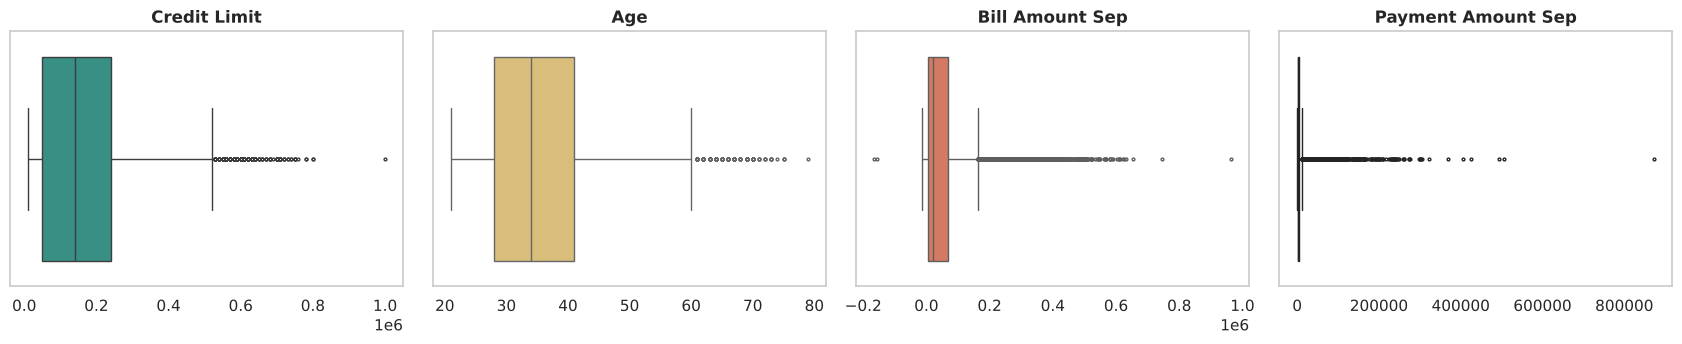

In [4]:
num_cols = ["Credit_Limit", "Age"] + BILL + PAY
rows = []
for c in num_cols:
    q1, q3 = raw[c].quantile([.25, .75])
    iqr = q3 - q1
    n = int(((raw[c] < q1 - 1.5 * iqr) | (raw[c] > q3 + 1.5 * iqr)).sum())
    rows.append((c, raw[c].min(), raw[c].max(), n, round(n / len(raw) * 100, 1)))
outliers = pd.DataFrame(rows, columns=["Variable", "Min", "Max", "IQR outliers", "% of rows"])
display(outliers.style.hide(axis="index").format({"Min": "{:,.0f}", "Max": "{:,.0f}", "% of rows": "{:.1f}"}))

neg = (raw[BILL] < 0).any(axis=1)
zero = (raw[BILL] == 0).all(axis=1)
zero_late = zero & (raw["Repayment_Status_Sep"] == 1)
print(f"Negative bill in at least one month: {neg.sum():,} customers ({neg.mean():.1%}); "
      f"default rate {y[neg].mean():.1%} vs {y[~neg].mean():.1%} for the rest")
print(f"Zero bill in all six months: {zero.sum():,} customers; {zero_late.sum():,} of them are marked "
      f"'1 month late' in September; default rate {y[zero].mean():.1%}")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, c, col in zip(axes, ["Credit_Limit", "Age", "Bill_Amount_Sep", "Payment_Amount_Sep"], [TEAL, GOLD, CORAL, NAVY]):
    sns.boxplot(x=raw[c], ax=ax, color=col, fliersize=2)
    ax.set_title(c.replace("_", " "))
    ax.set_xlabel("")
save("01_outliers")

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>Between 8% and 10% of rows are flagged in each bill and payment column, which is the normal long right tail of spending data rather than entry error, so no records are removed. <b>1,930 customers (6.4%)</b> show a negative bill, i.e. a credit balance, and they default less (16.5% vs 22.5%). One anomaly needs the data owner's attention: <b>866 customers were billed nothing for six months, yet 541 are marked one month late</b> in September (default rate 36.6%).</div>

### 5. Behavioural features

*Six months of raw columns are condensed into measures of delay, utilization and repayment effort.*

In [5]:
data = raw.copy()
data["Education_Level"] = data["Education_Level"].replace({0: 4, 5: 4, 6: 4})
data["Marital_Status"] = data["Marital_Status"].replace({0: 3})

late = data[STATUS].clip(lower=0)
bill_total = data[BILL].sum(axis=1)
data["Avg_Delay"] = late.mean(axis=1)
data["Max_Delay"] = late.max(axis=1)
data["Months_Delayed"] = (data[STATUS] > 0).sum(axis=1)
data["Status_Trend"] = data["Repayment_Status_Sep"] - data["Repayment_Status_Apr"]
data["Avg_Bill"] = data[BILL].mean(axis=1)
data["Avg_Payment"] = data[PAY].mean(axis=1)
data["Utilization"] = data["Avg_Bill"] / data["Credit_Limit"]
data["Payment_Ratio"] = (data[PAY].sum(axis=1) / bill_total.where(bill_total > 0)).fillna(1).clip(0, 1)
data["Bill_Trend"] = (data["Bill_Amount_Sep"] - data["Bill_Amount_Apr"]) / data["Credit_Limit"]
data["Zero_Payment_Months"] = (data[PAY] == 0).sum(axis=1)

ENGINEERED = ["Months_Delayed", "Max_Delay", "Avg_Delay", "Zero_Payment_Months", "Utilization", "Payment_Ratio"]
display(data.groupby("Default_Next_Month")[ENGINEERED].mean().T.rename(columns={0: "No default", 1: "Default"}).round(2))

Default_Next_Month,No default,Default
Months_Delayed,0.50,2.00
Max_Delay,0.47,1.43
Avg_Delay,0.16,0.71
Zero_Payment_Months,1.08,1.76
Utilization,0.35,0.45
Payment_Ratio,0.37,0.28


<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>Defaulters were late in about <b>2.0 of the six months on average, against 0.5</b> for customers who did not default, and skipped payment in 1.8 months versus 1.1. They also use more of their limit (45% vs 35%) and repay a smaller share of what they are billed (28% vs 37%).</div>

### 6. Target distribution

*How many customers default next month.*

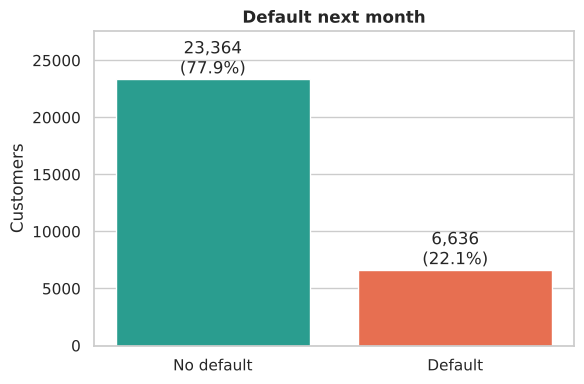

In [6]:
counts = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["No default", "Default"], counts.values, color=[TEAL, CORAL])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(y):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel("Customers")
ax.set_title("Default next month")
save("02_target")

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br><b>22.1% of customers (6,636 of 30,000) default</b>, about one in 4.5. Because defaults are a minority, the rest of the analysis compares default <i>rates</i> between groups rather than relying on overall averages.</div>

### 7. Customer profile

*Age, credit limit and the composition of the portfolio.*

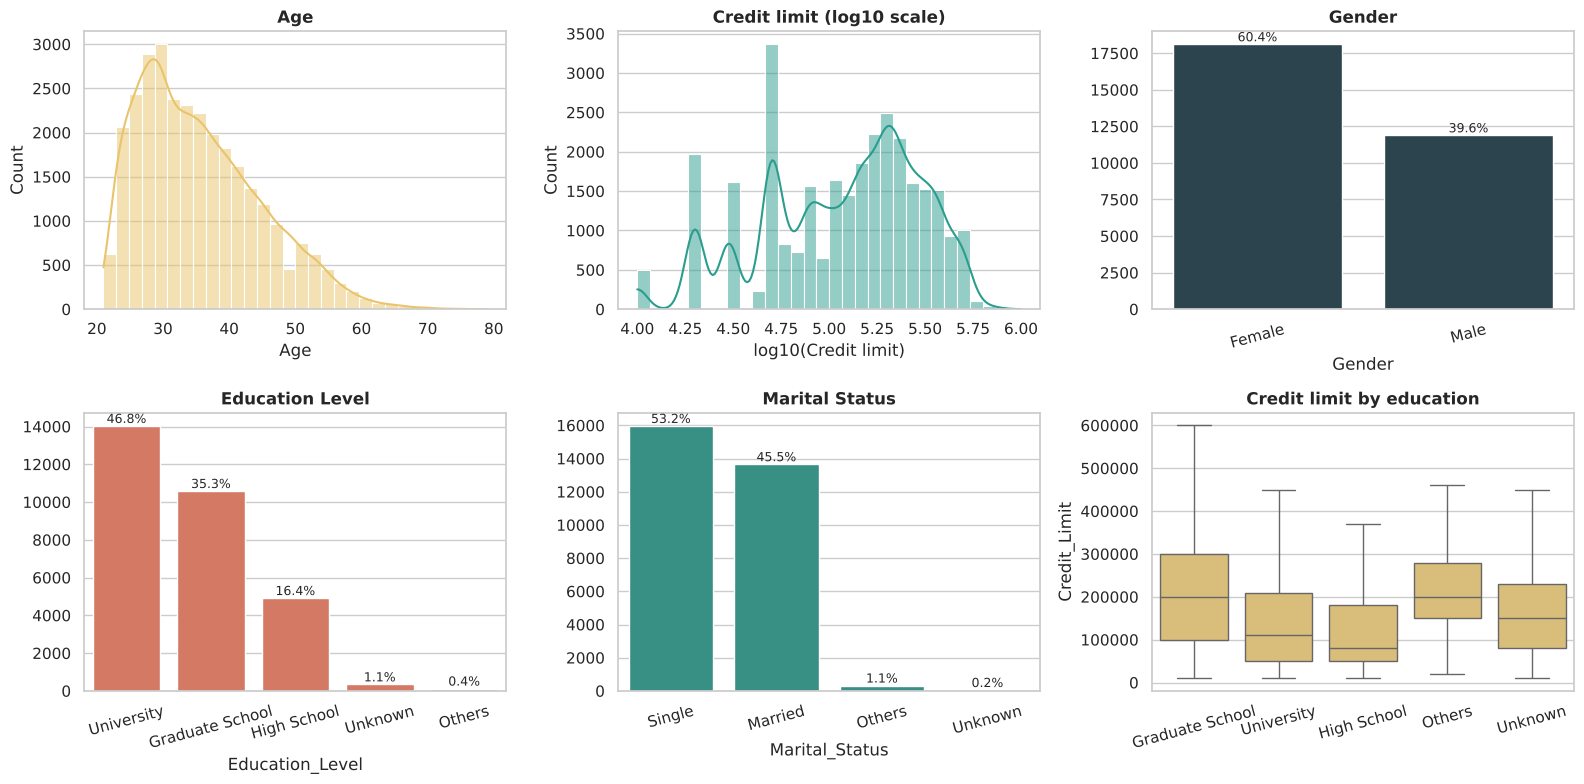

In [7]:
order = ["Graduate School", "University", "High School", "Others", "Unknown"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(raw["Age"], bins=30, kde=True, color=GOLD, ax=axes[0, 0])
axes[0, 0].set_title("Age")
sns.histplot(np.log10(raw["Credit_Limit"]), bins=30, kde=True, color=TEAL, ax=axes[0, 1])
axes[0, 1].set_title("Credit limit (log10 scale)")
axes[0, 1].set_xlabel("log10(Credit limit)")
for ax, col, colr in zip([axes[0, 2], axes[1, 0], axes[1, 1]], ["Gender", "Education_Level", "Marital_Status"], [NAVY, CORAL, TEAL]):
    vc = df[col].value_counts()
    sns.barplot(x=vc.index, y=vc.values, ax=ax, color=colr)
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v / len(df):.1%}", ha="center", va="bottom", fontsize=9)
    ax.set_title(col.replace("_", " "))
    ax.tick_params(axis="x", rotation=15)
sns.boxplot(data=df, x="Education_Level", y="Credit_Limit", order=order, color=GOLD, showfliers=False, ax=axes[1, 2])
axes[1, 2].set_title("Credit limit by education")
axes[1, 2].set_xlabel("")
axes[1, 2].tick_params(axis="x", rotation=15)
save("03_profile")

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>The portfolio is 60% female and 82% University or Graduate School educated, with a median age of 34. Limits are right-skewed (median 140,000, mean 167,484) and <b>track education closely</b>: the median limit is 200,000 for Graduate School, 110,000 for University and 80,000 for High School.</div>

### 8. Default rate by demographic group

*Group-level default rates with chi-square tests and Cramer's V as an effect-size measure.*

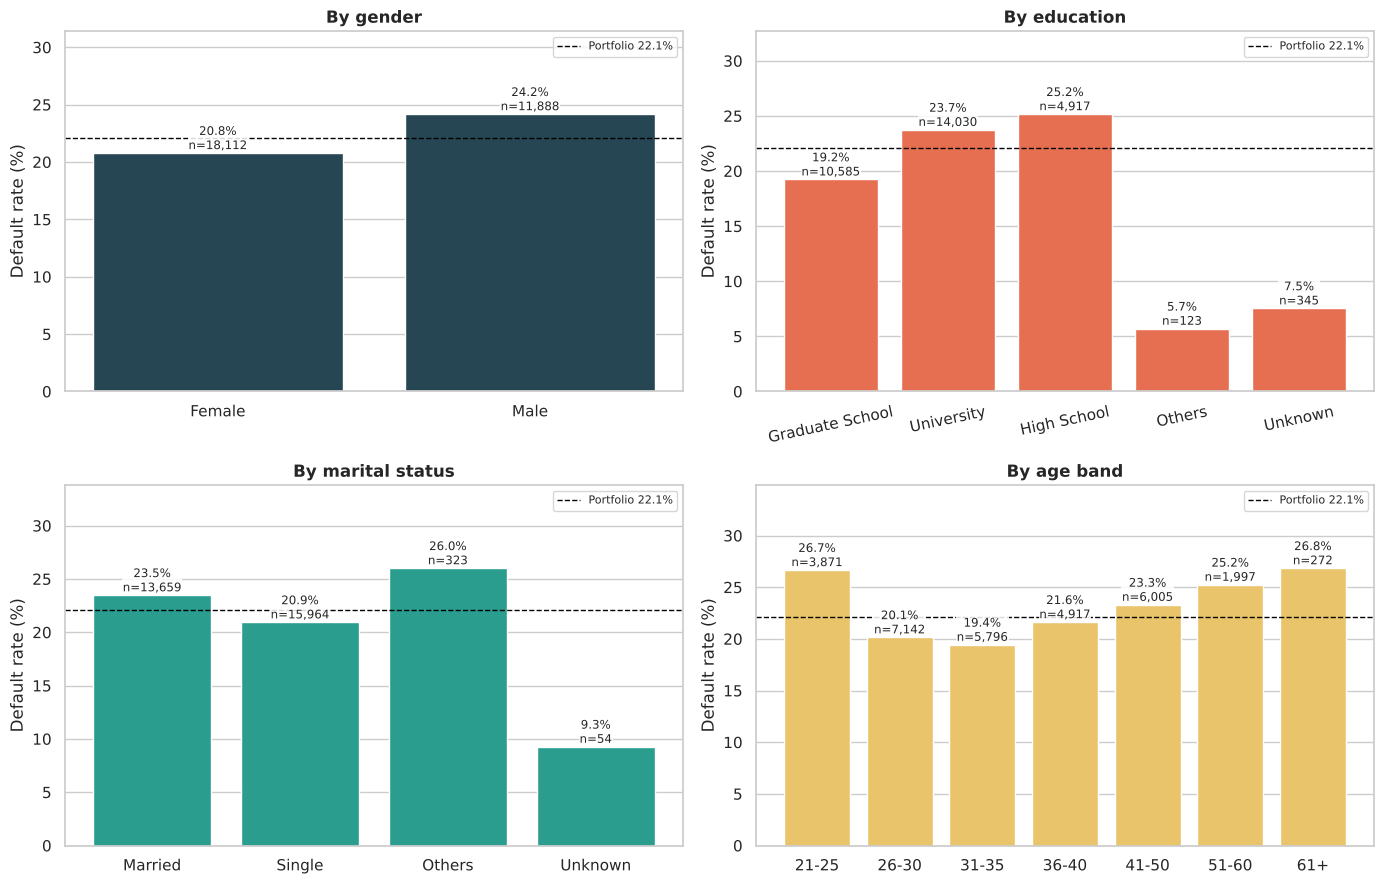

Variable,Chi-square p-value,Cramer's V
Gender,4.94e-12,0.040
Education_Level,1.09e-33,0.073
Marital_Status,8.83e-08,0.034


In [8]:
age_band = pd.cut(raw["Age"], [20, 25, 30, 35, 40, 50, 60, 80], labels=["21-25", "26-30", "31-35", "36-40", "41-50", "51-60", "61+"])
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
g_gender = rate_bar(axes[0, 0], df["Gender"], y, "By gender", NAVY)
g_edu = rate_bar(axes[0, 1], df["Education_Level"], y, "By education", CORAL, order=order, rot=12)
g_mar = rate_bar(axes[1, 0], df["Marital_Status"], y, "By marital status", TEAL, order=["Married", "Single", "Others", "Unknown"])
g_age = rate_bar(axes[1, 1], age_band, y, "By age band", GOLD)
save("04_demographics")


def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    return np.sqrt(stats.chi2_contingency(ct)[0] / (ct.values.sum() * (min(ct.shape) - 1)))


tests = pd.DataFrame([{"Variable": c, "Chi-square p-value": stats.chi2_contingency(pd.crosstab(df[c], y))[1],
                       "Cramer's V": cramers_v(df[c], y)} for c in ["Gender", "Education_Level", "Marital_Status"]])
display(tests.style.hide(axis="index").format({"Chi-square p-value": "{:.2e}", "Cramer's V": "{:.3f}"}))

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>All three differences are statistically significant, but the effects are small (Cramer's V of 0.03 to 0.07). Men default at 24.2% against 20.8% for women; education runs from 19.2% (Graduate School) to 25.2% (High School); married customers sit at 23.5% against 20.9% for single customers. Age is U-shaped: 21-25 year-olds (26.7%) and customers over 50 (25% to 27%) default more than 26-35 year-olds (19% to 20%).</div>

### 9. Age, credit limit, education and marital status together

*Cross-tabulated default rates show which relationships hold once a second factor is held constant.*

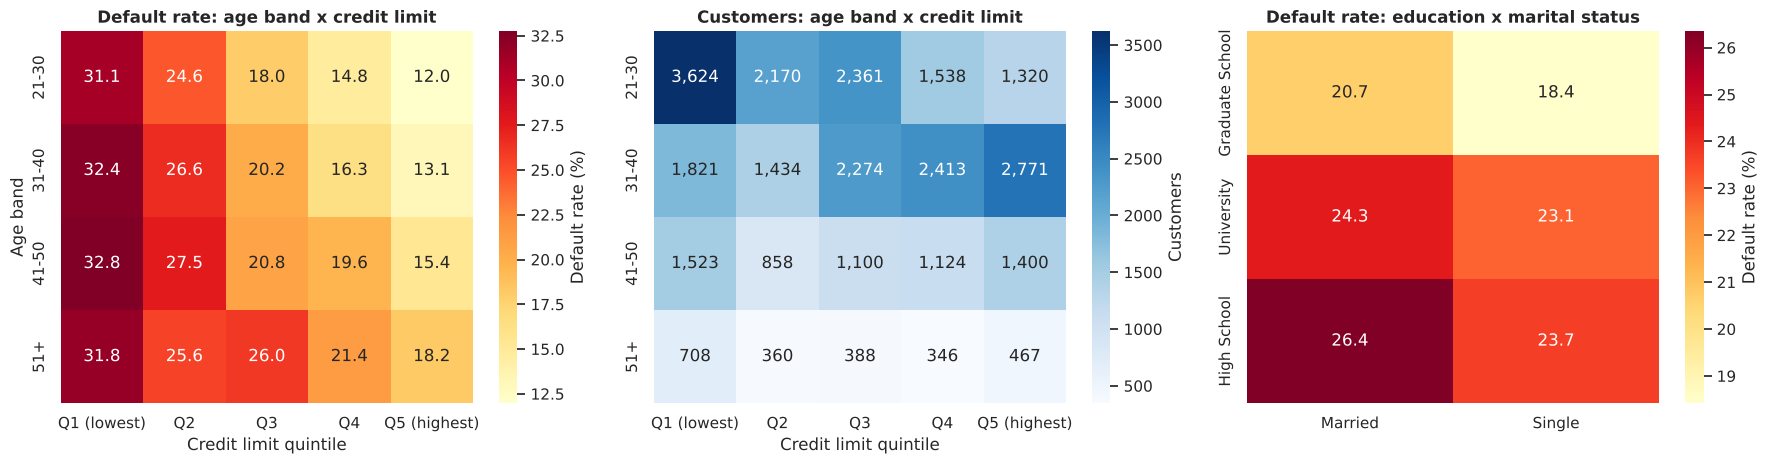

In [9]:
age4 = pd.cut(raw["Age"], [20, 30, 40, 50, 80], labels=["21-30", "31-40", "41-50", "51+"])
lim5 = pd.qcut(raw["Credit_Limit"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
rate_al = pd.crosstab(age4, lim5, values=y, aggfunc="mean") * 100
size_al = pd.crosstab(age4, lim5)

sub = data[data["Education_Level"].isin([1, 2, 3]) & data["Marital_Status"].isin([1, 2])]
rate_em = sub.pivot_table(index="Education_Level", columns="Marital_Status", values="Default_Next_Month", aggfunc="mean") * 100
rate_em.index = ["Graduate School", "University", "High School"]
rate_em.columns = ["Married", "Single"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.heatmap(rate_al, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Default rate (%)"}, ax=axes[0])
axes[0].set_title("Default rate: age band x credit limit")
axes[0].set_xlabel("Credit limit quintile"); axes[0].set_ylabel("Age band")
sns.heatmap(size_al, annot=True, fmt=",d", cmap="Blues", cbar_kws={"label": "Customers"}, ax=axes[1])
axes[1].set_title("Customers: age band x credit limit")
axes[1].set_xlabel("Credit limit quintile"); axes[1].set_ylabel("")
sns.heatmap(rate_em, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Default rate (%)"}, ax=axes[2])
axes[2].set_title("Default rate: education x marital status")
axes[2].set_xlabel(""); axes[2].set_ylabel("")
for ax in axes:
    ax.grid(False)
save("05_age_limit_education")

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br><b>Credit limit matters more than age.</b> Within every age band, default falls steadily as the limit rises (21-30: 31.1% in the lowest quintile, 12.0% in the highest). The higher default of the youngest customers is largely a limit effect, because 3,624 of them sit in the lowest-limit quintile; inside that quintile the gap by age is small (31.1% for 21-30 against 32.8% for 41-50). Education keeps its order in both marital groups, and married customers are 1 to 3 points higher throughout.</div>

### 10. Repayment status

*Default rate for each repayment status in the most recent month (September), alongside the size of each group.*

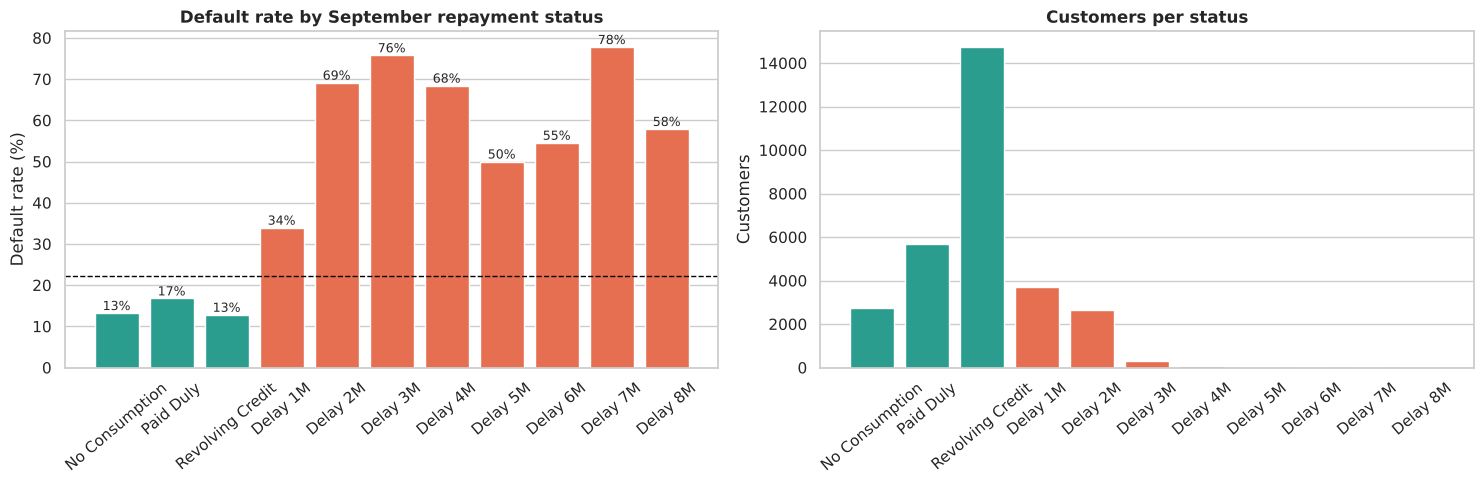

In [10]:
status_order = [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]
short = lambda s: status_map[s].replace(" Months", "M").replace(" Month", "M")
sep = raw["Repayment_Status_Sep"]
g_sep = pd.DataFrame({"s": sep, "y": y}).groupby("s")["y"].agg(["mean", "count"]).reindex(status_order)
colors = [TEAL if s <= 0 else CORAL for s in g_sep.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar([short(s) for s in g_sep.index], g_sep["mean"] * 100, color=colors)
for i, m in enumerate(g_sep["mean"]):
    axes[0].text(i, m * 100, f"{m * 100:.0f}%", ha="center", va="bottom", fontsize=9)
axes[0].axhline(y.mean() * 100, color="black", ls="--", lw=1)
axes[0].set_title("Default rate by September repayment status")
axes[0].set_ylabel("Default rate (%)")
axes[1].bar([short(s) for s in g_sep.index], g_sep["count"], color=colors)
axes[1].set_title("Customers per status")
axes[1].set_ylabel("Customers")
for ax in axes:
    ax.tick_params(axis="x", rotation=40)
save("06_repayment_status")

<div style="border-left:5px solid #e76f51;background:#fdf1ec;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#e76f51">Finding</b><br><b>Repayment status is the strongest single signal.</b> Customers who are current or revolving default at 13% to 17%; one month late raises that to 33.9% and two months late to 69.1%. About 10% of customers are two or more months late, and roughly seven in ten of them default. More than half of all defaulters (52%) were already late in September, so the first one or two months of delay form the practical early-warning window.</div>

### 11. Delay in every month

*Default rate for each repayment status in each of the six months.*

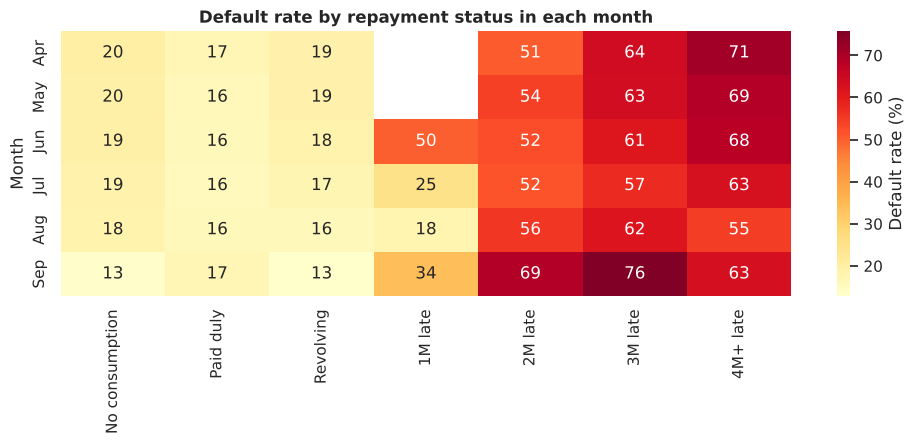

In [11]:
cap = lambda s: s.clip(upper=4)
heat = pd.DataFrame({m: pd.DataFrame({"s": cap(raw[f"Repayment_Status_{m}"]), "y": y}).groupby("s")["y"].mean()
                     for m in MONTHS}).T * 100
heat.columns = ["No consumption", "Paid duly", "Revolving", "1M late", "2M late", "3M late", "4M+ late"]

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "Default rate (%)"}, ax=ax)
ax.set_title("Default rate by repayment status in each month")
ax.set_ylabel("Month")
ax.grid(False)
save("07_status_by_month")

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>Being two or more months late is associated with a 51% to 76% default rate in <b>every</b> month, not only the latest one, so the whole payment history carries information. The empty '1M late' cells are a coding quirk of the source: that status appears in 3,688 September records but in only 0, 0, 2, 4 and 28 records in the earlier months. 'Paid duly' (16.8%) is not safer than 'revolving' (12.8%), so the codes behave as categories rather than a strict scale.</div>

### 12. Delay history features

*Number of delayed months, worst delay and months with no payment, against default rate.*

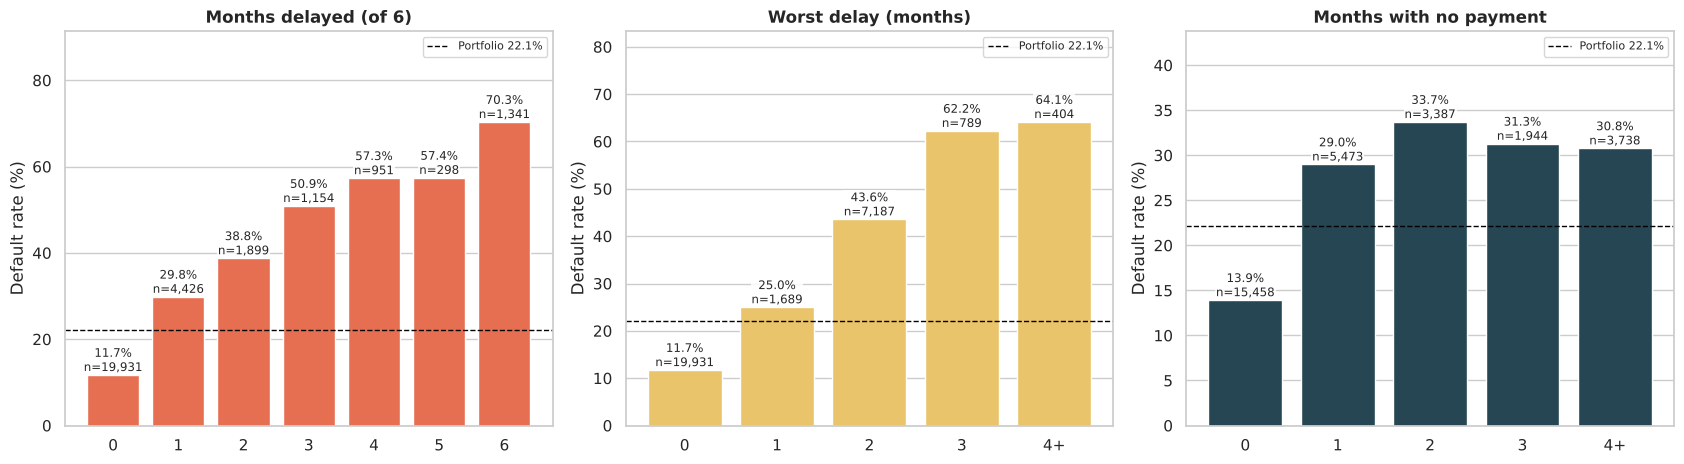

,Customers,Defaults,Default_rate,Share of customers,Share of all defaults
Segment,,,,,
Never late,"19,931","2,334",11.7%,66.4%,35.2%
1 month late,"4,426","1,320",29.8%,14.8%,19.9%
2 months late,"1,899",736,38.8%,6.3%,11.1%
3+ months late,"3,744","2,246",60.0%,12.5%,33.8%


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
g_md = rate_bar(axes[0], data["Months_Delayed"], y, "Months delayed (of 6)", CORAL)
worst = data["Max_Delay"].clip(upper=4).astype(int).astype(str).replace({"4": "4+"})
rate_bar(axes[1], worst, y, "Worst delay (months)", GOLD)
zp = data["Zero_Payment_Months"].clip(upper=4).astype(int).astype(str).replace({"4": "4+"})
rate_bar(axes[2], zp, y, "Months with no payment", NAVY)
save("08_delay_history")

seg = data.assign(Segment=pd.cut(data["Months_Delayed"], [-1, 0, 1, 2, 6],
                                 labels=["Never late", "1 month late", "2 months late", "3+ months late"]))
segments = seg.groupby("Segment", observed=True)["Default_Next_Month"].agg(Customers="count", Defaults="sum", Default_rate="mean")
segments["Share of customers"] = segments["Customers"] / len(data)
segments["Share of all defaults"] = segments["Defaults"] / segments["Defaults"].sum()
display(segments.style.format({"Customers": "{:,}", "Defaults": "{:,}", "Default_rate": "{:.1%}",
                               "Share of customers": "{:.1%}", "Share of all defaults": "{:.1%}"}))

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>Two thirds of customers (66%) were never late in six months, and only 11.7% of them default. Risk climbs with every additional late month: 29.8% after one, 50.9% after three and 70.3% when all six months were late. Simple counts like these are easy to monitor and explain.</div>

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Segmentation</b><br>Grouping customers by delay history gives a simple risk segmentation: never late (66.4% of customers) default at 11.7%; one late month (14.8%) at 29.8%; two late months (6.3%) at 38.8%; three or more late months (12.5%) at 60.0%. The 3+ group is an eighth of the portfolio but holds <b>34% of all defaults</b>, and the 33.6% of customers with any late month hold <b>65%</b> of them.</div>

### 13. Utilization and payment ratio

*Default rate against the share of the limit in use and the share of the bill actually repaid.*

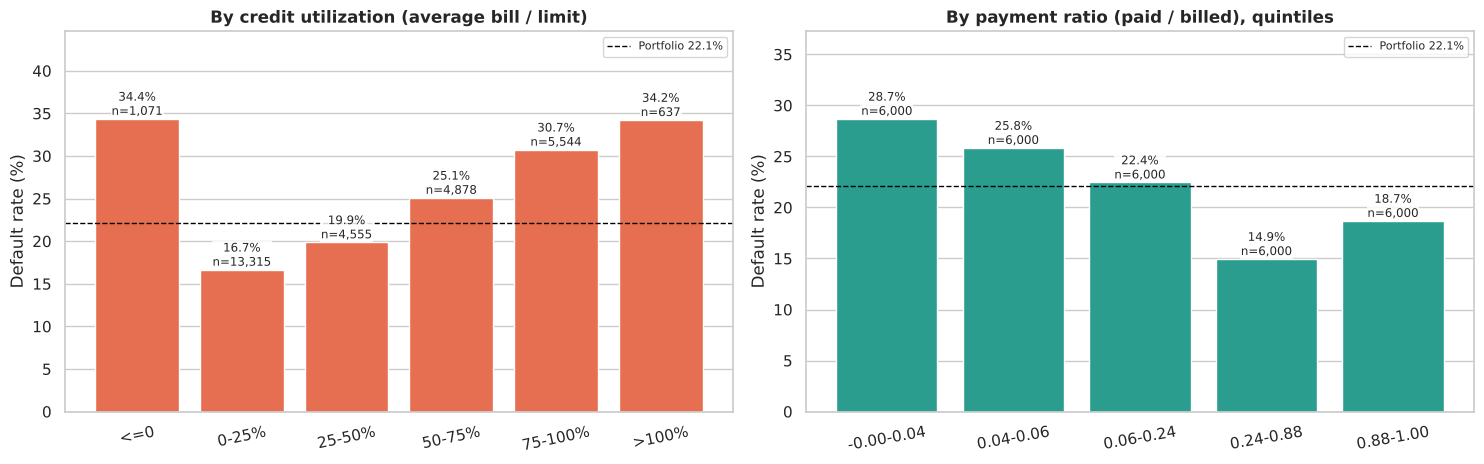

In [13]:
util_band = pd.cut(data["Utilization"], [-10, 0, .25, .5, .75, 1, 100],
                   labels=["<=0", "0-25%", "25-50%", "50-75%", "75-100%", ">100%"])
pr_q = pd.qcut(data["Payment_Ratio"], 5, duplicates="drop")
pr_q = pr_q.cat.rename_categories([f"{i.left:.2f}-{i.right:.2f}" for i in pr_q.cat.categories])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
rate_bar(axes[0], util_band, y, "By credit utilization (average bill / limit)", CORAL, rot=12)
rate_bar(axes[1], pr_q, y, "By payment ratio (paid / billed), quintiles", TEAL, rot=10)
save("09_utilization_payment")

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>Default rises with utilization: 16.7% at 0-25%, 30.7% at 75-100% and 34.2% above the limit. Customers who repay under 6.5% of their bills default at 26% to 29%, against about 15% for those repaying 25% to 88%. The 34% default rate shown for zero or negative utilization comes mostly from the 866 zero-bill accounts noted earlier, so it should not be read as low utilization being risky.</div>

### 14. Delay and utilization combined

*A two-factor risk map: how utilization changes risk for customers with different delay histories.*

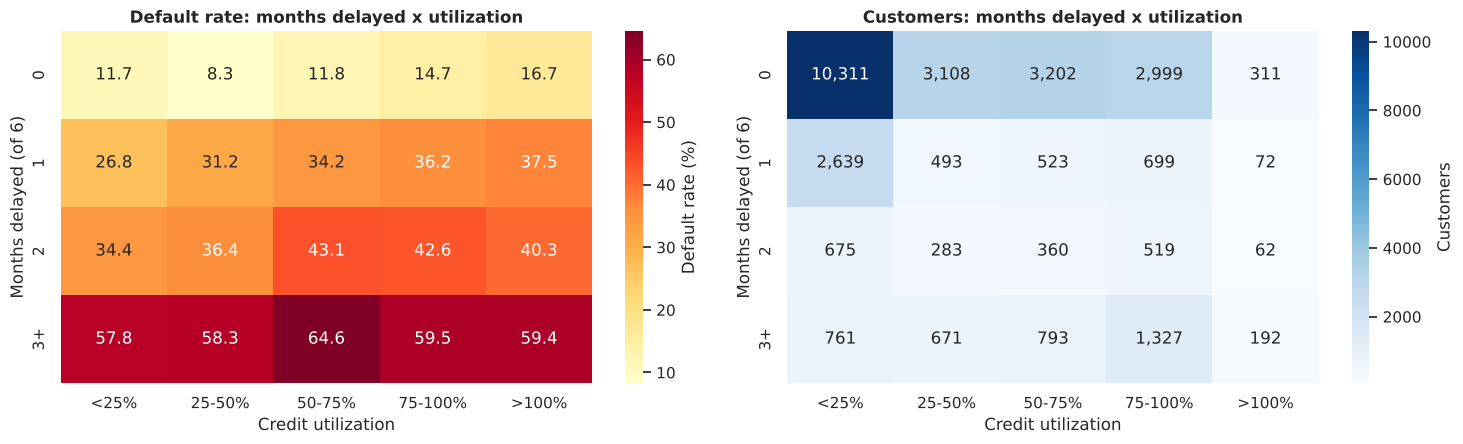

In [14]:
md_ = data["Months_Delayed"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
ub = pd.cut(data["Utilization"], [-10, .25, .5, .75, 1, 100], labels=["<25%", "25-50%", "50-75%", "75-100%", ">100%"])
rate_du = pd.crosstab(md_, ub, values=y, aggfunc="mean") * 100
size_du = pd.crosstab(md_, ub)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
sns.heatmap(rate_du, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Default rate (%)"}, ax=axes[0])
axes[0].set_title("Default rate: months delayed x utilization")
sns.heatmap(size_du, annot=True, fmt=",d", cmap="Blues", cbar_kws={"label": "Customers"}, ax=axes[1])
axes[1].set_title("Customers: months delayed x utilization")
for ax in axes:
    ax.set_xlabel("Credit utilization"); ax.set_ylabel("Months delayed (of 6)"); ax.grid(False)
save("10_delay_utilization")

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br><b>Delay history outweighs utilization.</b> Customers who were never late default at 8% to 17% at every utilization level, and those late in three or more months default at 58% to 65% at every level. Utilization adds a moderate lift inside each group (never late: 11.7% to 16.7%; one late month: 26.8% to 37.5%). Two segments stand out: <b>never late with utilization under 25%</b> (10,311 customers, 11.7% default) and <b>two or more late months with utilization above 75%</b> (2,100 customers, 54.7%).</div>

### 15. Bills and payments over time

*Average monthly bill and payment for each outcome group.*

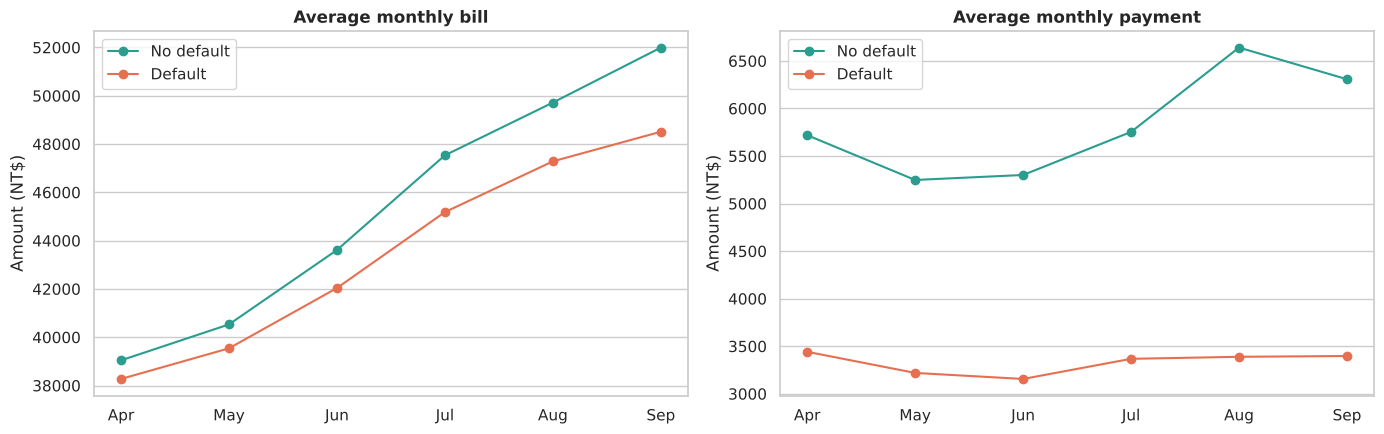

In [15]:
mean_bill = pd.DataFrame({n: raw.loc[y == v, BILL].mean().values for n, v in [("No default", 0), ("Default", 1)]}, index=MONTHS)
mean_pay = pd.DataFrame({n: raw.loc[y == v, PAY].mean().values for n, v in [("No default", 0), ("Default", 1)]}, index=MONTHS)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, tab, title in [(axes[0], mean_bill, "Average monthly bill"), (axes[1], mean_pay, "Average monthly payment")]:
    ax.plot(tab.index, tab["No default"], marker="o", color=TEAL, label="No default")
    ax.plot(tab.index, tab["Default"], marker="o", color=CORAL, label="Default")
    ax.set_title(title)
    ax.set_ylabel("Amount (NT$)")
    ax.legend()
save("11_bill_payment_trends")

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>Bills are similar for both groups and are slightly <i>lower</i> for defaulters in September (48.5k against 52.0k), but defaulters <b>pay 40% to 50% less every month</b> (September: 3.4k against 6.3k). The difference lies in repayment behaviour, not in how much customers spend.</div>

### 16. Distributions by outcome

*Violin plots comparing the spread of key behavioural variables for customers who did and did not default.*

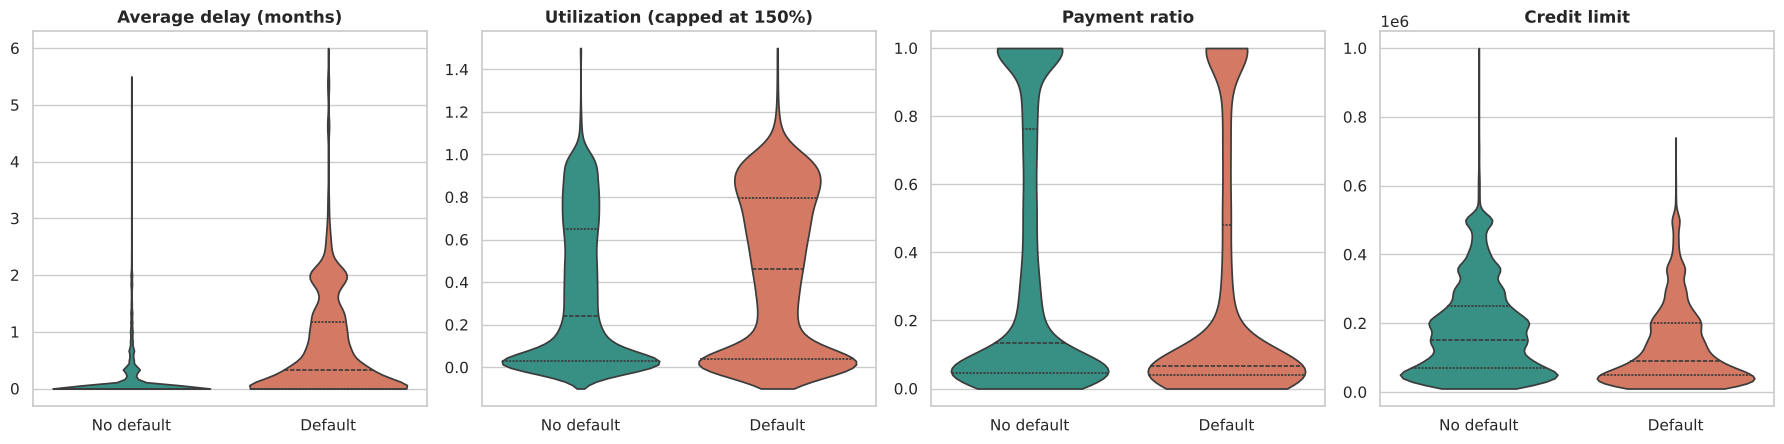

In [16]:
plot_df = data.assign(Outcome=y.map({0: "No default", 1: "Default"}))
plot_df["Utilization_c"] = plot_df["Utilization"].clip(-0.1, 1.5)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
panels = [("Avg_Delay", "Average delay (months)"), ("Utilization_c", "Utilization (capped at 150%)"),
          ("Payment_Ratio", "Payment ratio"), ("Credit_Limit", "Credit limit")]
for ax, (col, title) in zip(axes, panels):
    sns.violinplot(data=plot_df, x="Outcome", y=col, order=["No default", "Default"], hue="Outcome",
                   hue_order=["No default", "Default"], palette=[TEAL, CORAL], legend=False, cut=0, inner="quartile", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
save("12_distributions")

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>Behavioural variables separate the two groups clearly. Defaulters typically use about <b>twice the share of their limit</b> (median 46% against 24%) and repay about half as much of what they are billed (median 6.5% against 13.4%). The median non-defaulter has no late month at all, while the median defaulter averages a third of a month of delay. Credit limits are lower for defaulters (median 90,000 against 150,000).</div>

### 17. Bills, payments and utilization

*Customer-level scatter plots (random sample of 5,000) showing how billing, repayment and utilization relate.*

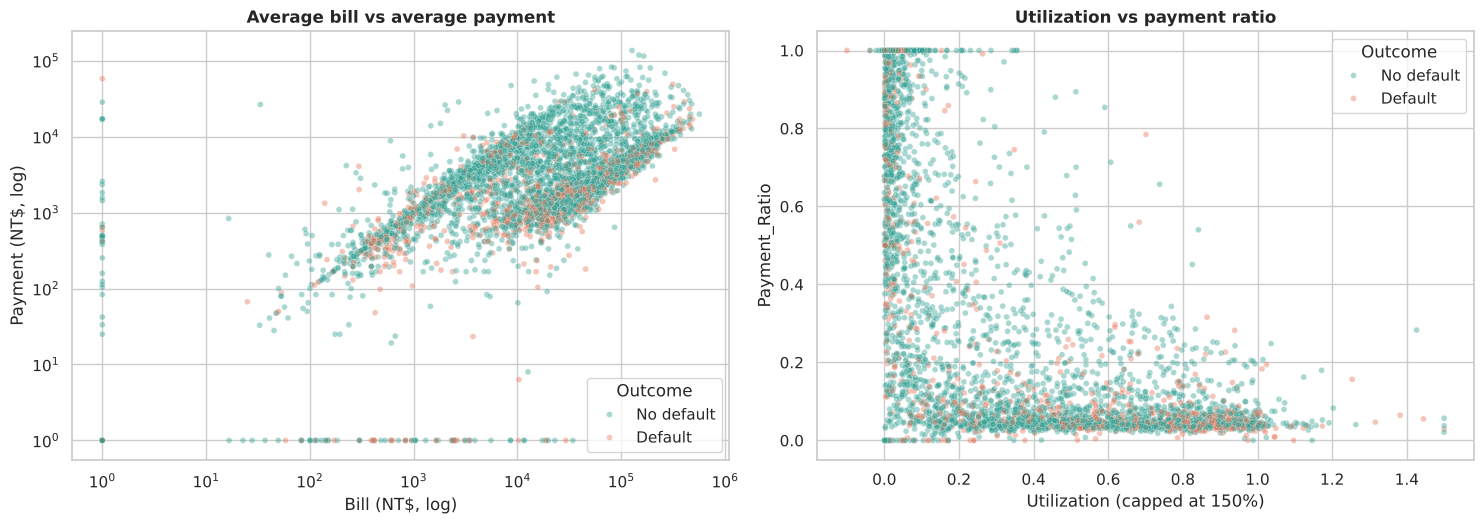

In [17]:
s = plot_df.sample(5000, random_state=SEED).copy()
s["Bill (NT$, log)"] = s["Avg_Bill"].clip(lower=1)          # non-positive averages are shown at 1
s["Payment (NT$, log)"] = s["Avg_Payment"].clip(lower=1)    # zero payments are shown at 1
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
sns.scatterplot(data=s, x="Bill (NT$, log)", y="Payment (NT$, log)", hue="Outcome", hue_order=["No default", "Default"],
                palette=[TEAL, CORAL], alpha=.4, s=18, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Average bill vs average payment")
sns.scatterplot(data=s, x="Utilization_c", y="Payment_Ratio", hue="Outcome", hue_order=["No default", "Default"],
                palette=[TEAL, CORAL], alpha=.4, s=18, ax=axes[1])
axes[1].set_title("Utilization vs payment ratio")
axes[1].set_xlabel("Utilization (capped at 150%)")
for ax in axes:
    ax.grid(True)
save("13_scatter_relationships")

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>Bills and payments are only loosely related (correlation 0.34). Among customers with an average bill above 50,000, the <b>5,657 who repay less than 5% default at 23.8%</b>, whereas the 630 who repay at least 25% default at only 6.5%. Utilization and payment ratio move in opposite directions (correlation -0.68): the heaviest users of their limit tend to repay the smallest share.</div>

### 18. Pairwise relationships

*Pair plot of age, limit and the main behavioural variables (random sample of 2,000 customers).*

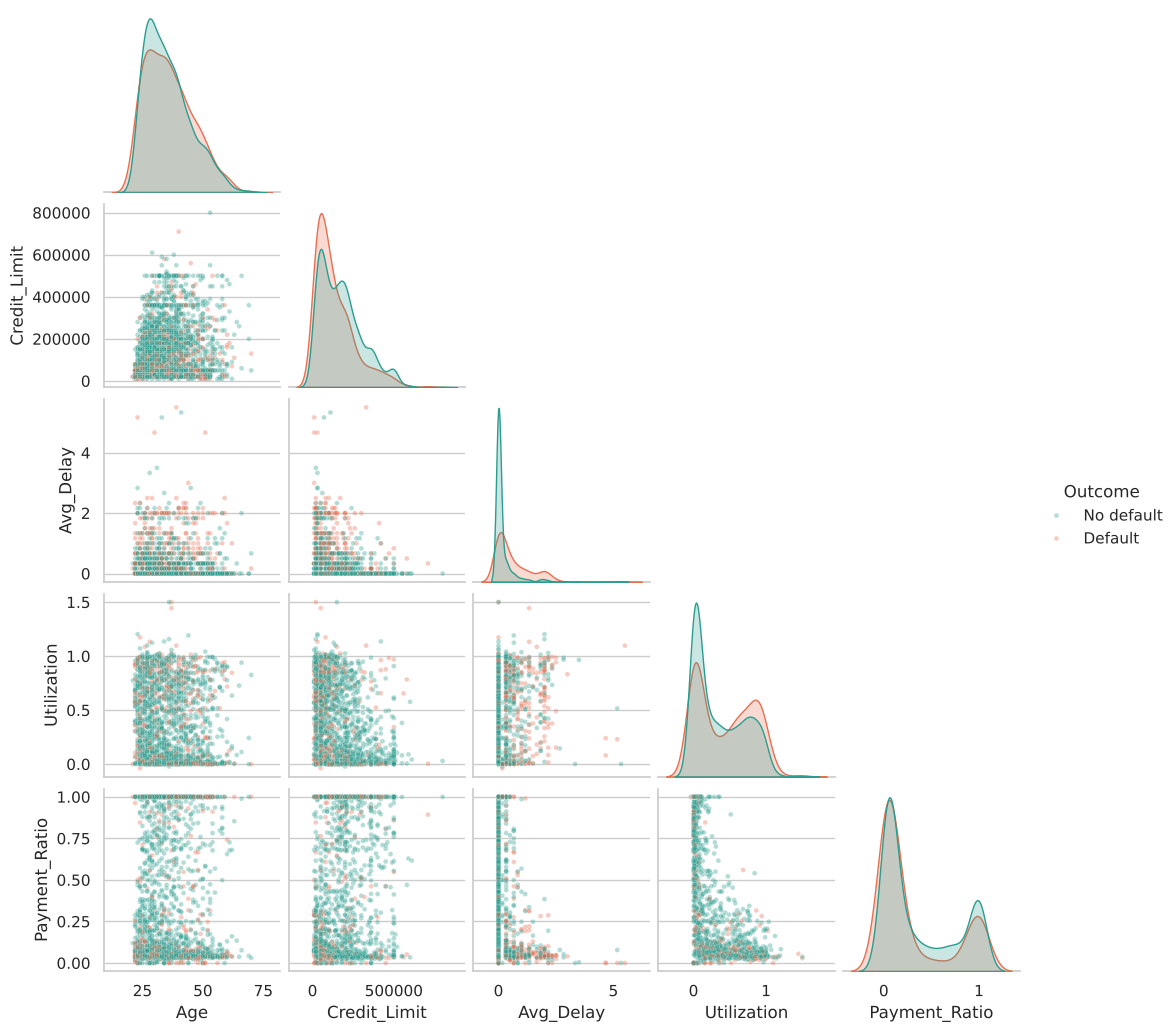

In [18]:
pp = plot_df.sample(2000, random_state=SEED)[["Age", "Credit_Limit", "Avg_Delay", "Utilization_c", "Payment_Ratio", "Outcome"]]
pp = pp.rename(columns={"Utilization_c": "Utilization"})
g = sns.pairplot(pp, hue="Outcome", hue_order=["No default", "Default"], palette=[TEAL, CORAL], corner=True,
                 diag_kind="kde", plot_kws=dict(alpha=.35, s=12), diag_kws=dict(common_norm=False), height=2.1)
g.figure.savefig(f"{FIG_DIR}/14_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>The diagonal densities show the same pattern as the violin plots: age is almost identical for the two outcomes, credit limit is shifted lower for defaulters, and average delay, utilization and payment ratio show the clearest separation.</div>

### 19. Correlation structure

*Pearson correlations between selected variables, and the strongest correlates of default.*

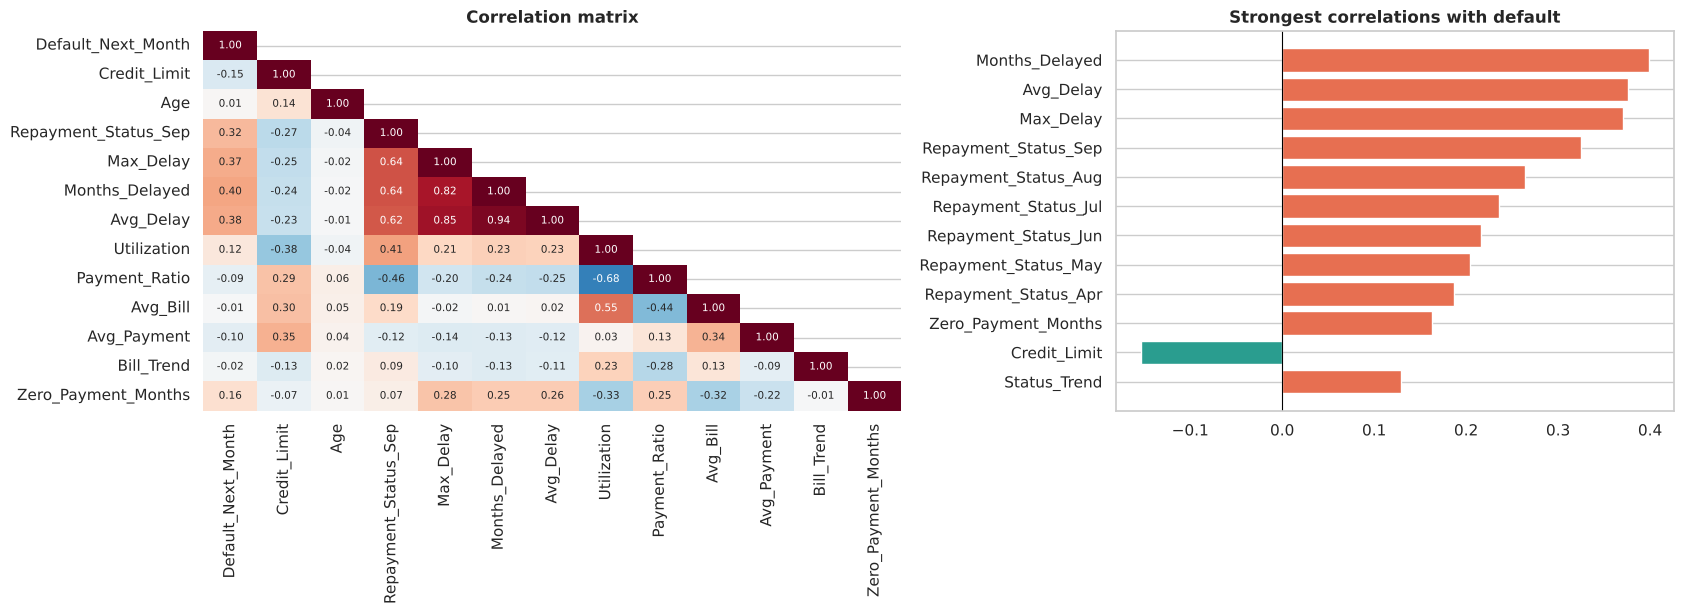

Correlation between the six monthly bill columns: 0.80 to 0.95
Credit limit: -0.15   Age: 0.01


In [19]:
sel = ["Default_Next_Month", "Credit_Limit", "Age", "Repayment_Status_Sep", "Max_Delay", "Months_Delayed", "Avg_Delay",
       "Utilization", "Payment_Ratio", "Avg_Bill", "Avg_Payment", "Bill_Trend", "Zero_Payment_Months"]
num_all = data.select_dtypes("number").drop(columns=["Customer_ID"])
corr_target = num_all.corr()["Default_Next_Month"].drop("Default_Next_Month").sort_values(key=np.abs, ascending=False)
bill_corr = raw[BILL].corr().values[np.triu_indices(6, 1)]

fig, axes = plt.subplots(1, 2, figsize=(17, 6.3), gridspec_kw={"width_ratios": [1.25, 1]})
mask = np.triu(np.ones((len(sel), len(sel)), dtype=bool), 1)
sns.heatmap(data[sel].corr(), mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            cbar=False, annot_kws={"size": 7.5}, ax=axes[0])
axes[0].set_title("Correlation matrix")
top = corr_target.head(12)[::-1]
axes[1].barh(top.index, top.values, color=[CORAL if v > 0 else TEAL for v in top.values])
axes[1].axvline(0, color="black", lw=.8)
axes[1].set_title("Strongest correlations with default")
save("15_correlations")
print(f"Correlation between the six monthly bill columns: {bill_corr.min():.2f} to {bill_corr.max():.2f}")
print(f"Credit limit: {corr_target['Credit_Limit']:.2f}   Age: {corr_target['Age']:.2f}")

<div style="border-left:5px solid #2a9d8f;background:#eef7f5;padding:12px 16px;border-radius:4px;line-height:1.55"><b style="color:#2a9d8f">Finding</b><br>The strongest correlates of default are the engineered delay measures: months delayed (0.40), average delay (0.38) and worst delay (0.37), ahead of the raw September status (0.32). Credit limit is negatively correlated (-0.15) and age is essentially uncorrelated (0.01). The six monthly bills correlate 0.80 to 0.95 with one another and are largely redundant, which is why they are summarised as average bill and utilization.</div>

### 20. Recommendations

**Act on repayment behaviour**
1. **Intervene at the first missed payment.** Default rises from 13.8% for customers who are current to 33.9% after one month of delay and 69.1% after two. Contact the customer (reminder, payment plan, due-date change) before the second month is missed.
2. **Segment customers by delay history and manage each group differently.** Never late (66% of customers, 11.7% default): standard service and candidates for limit increases. One or two late months (21%, 30% to 39%): reminders and payment plans. Three or more late months (12.5%, 60%): collections and limit freezes.
3. **Monitor utilization and repayment effort.** Default is 16.7% below 25% utilization but 30.7% at 75-100% and 34.2% above the limit; customers repaying under 6.5% of their bill default at 26% to 29%. Alerts at 75% utilization and for repeated near-zero payments are low-cost triggers.
4. **Review limit policy.** Customers with limits of 50,000 or less default at 31.8% against 13.8% in the top quintile, a gradient that holds in every age band. Avoid limit increases for customers who are highly utilized or recently late.

**Data and governance**
5. **Resolve the source-data questions** before relying on the findings: obtain a data dictionary for the undocumented education, marital and repayment codes, and investigate the 866 zero-bill accounts (541 flagged as late).
6. **Keep demographics out of credit decisions.** Gender, education and marital status differ only slightly in default rate (Cramer's V of 0.07 or less), while credit limit and repayment behaviour explain far more.

**Limitations.** A descriptive analysis of one six-month snapshot from 2005: it shows associations rather than causes and has no income or employment data. Re-run the notebook on current data before acting on the thresholds.